# 5. Сходимость и теорема Лакса–Рихтмайера

Пусть при уменьшении шага сетки вдвое ошибка **одного шага** уменьшается вчетверо. Означает ли это, что результат **в конце расчёта** станет вчетверо точнее?

Для схемы переноса с $\tau=h/2$ ответ другой. До того же физического момента придётся сделать вдвое больше шагов. Если внесённые на этих шагах ошибки складываются, выигрыш к концу расчёта будет примерно двукратным. Но прежние ошибки могут ещё и затухать, менять знак или расти. Чтобы выяснить, что с ними происходит, запишем уравнение для самой ошибки.

## 1. Что происходит с ошибкой за один шаг?

Пусть $\mathbf U^s$ — вычисленный профиль на шаге $s$, а $\mathbf u^s$ — значения точного решения в тех же узлах в момент $t_s=s\tau$. Их разность называют **глобальной ошибкой** на этом шаге:

$$
\mathbf e^s=\mathbf U^s-\mathbf u^s.
$$

Обозначим через $B$ линейный оператор одного шага схемы. Для вычисленного решения по определению

$$
\mathbf U^{s+1}=B\mathbf U^s.
$$

Если начать с **точного** профиля $\mathbf u^s$, то в конце шага получится $B\mathbf u^s$. Расхождение с точным следующим слоем — это **локальный дефект** $\mathbf d^s=\mathbf u^{s+1}-B\mathbf u^s$. Поэтому для точного решения

$$
\mathbf u^{s+1}=B\mathbf u^s+\mathbf d^s.
$$

Теперь вычтем второе равенство из первого:

$$
\boxed{\mathbf e^{s+1}=B\mathbf e^s-\mathbf d^s.}
$$

У этой формулы два слагаемых. Величина $B\mathbf e^s$ показывает, что схема сделала с уже накопленной ошибкой. Величина $-\mathbf d^s$ — вклад только что выполненного шага. Знак минус появился потому, что дефект мы определили как «точное минус вычисленное», а глобальную ошибку — как «вычисленное минус точное».

Пусть начальный слой задан точно, а одна гармоника ошибки за шаг умножается на $g=1/2$. Если каждый шаг вносит одинаковый дефект $d=0{,}01$, то к концу третьего шага от первого вклада осталось $-0{,}0025$, от второго — $-0{,}005$, а третий только что добавил $-0{,}01$. В сумме получается $-0{,}0175$.

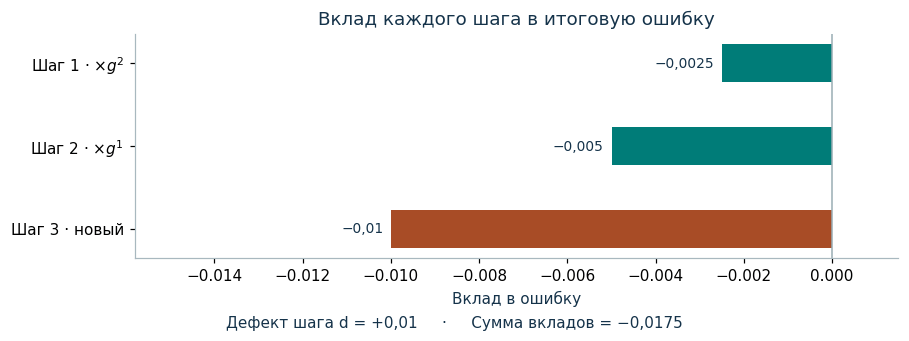

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as w
    from IPython.display import clear_output, display, Image
    from io import BytesIO
except ImportError:
    w = None

INK, TEAL, RUST = "#15334A", "#007C78", "#A84C26"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#A8B8BF", "axes.labelcolor": INK,
                     "text.color": INK, "font.size": 10, "axes.titlesize": 12,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})


def decimal(x, digits=3):
    return f"{x:.{digits}f}".rstrip("0").rstrip(".").replace(".", ",").replace("-", "−")


def experiment(figure, choices, curves=(), play=None):
    defaults = {key: value for key, (_, _, value) in choices.items()}
    if w is None:
        figure(**defaults)
        plt.show()
        return
    selectors = {}
    for key, (label, options, value) in choices.items():
        kwargs = dict(value=value, description=label, style={"description_width": "initial"},
                      layout=w.Layout(width="300px", max_width="100%"))
        if isinstance(options, range):
            selectors[key] = w.IntSlider(min=options[0], max=options[-1], step=options.step,
                                         continuous_update=False, **kwargs)
        else:
            selectors[key] = w.Dropdown(options=options, **kwargs)
    toggles = [w.ToggleButton(value=True, description=label,
                              layout=w.Layout(width="auto")) for label in curves]
    output = w.Output()

    def draw(change=None):
        values = {key: selector.value for key, selector in selectors.items()}
        if toggles:
            values["visible"] = [toggle.value for toggle in toggles]
        fig = figure(**values)
        with BytesIO() as buf:
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight", pad_inches=.1)
            picture = Image(data=buf.getvalue(), width=850)
        plt.close(fig)
        with output:
            clear_output(wait=True)
            display(picture)

    for control in [*selectors.values(), *toggles]:
        control.observe(draw, names="value")
    wrap = w.Layout(display="flex", flex_flow="row wrap")
    rows = [w.Box(list(selectors.values()), layout=wrap)]
    if play is not None:
        slider = selectors[play]
        player = w.Play(value=slider.value, min=slider.min, max=slider.max,
                        step=slider.step, interval=420, repeat=False)
        w.jslink((player, "value"), (slider, "value"))
        rows.append(player)
    if toggles:
        rows.append(w.Box(toggles, layout=wrap))
    display(w.VBox([*rows, output]))
    draw()


def history_figure(g=.5, M=3):
    age = M-1-np.arange(M)
    contributions = -.01 * float(g)**age
    pos = np.arange(M)
    fig, ax = plt.subplots(figsize=(8.15, 2.15+.28*M), constrained_layout=True)
    ax.axvline(0, color="#9AADB4", lw=1)
    ax.barh(pos, contributions, color=[TEAL]*(M-1)+[RUST], height=.46)
    labels = ["Шаг " + str(i+1) + (" · новый" if a == 0 else rf" · $\times g^{a}$")
              for i, a in enumerate(age)]
    ax.set_yticks(pos, labels)
    ax.invert_yaxis()
    span = max(abs(contributions))
    ax.set_xlim(-span*1.58, (span*1.58 if any(contributions>0) else .15*span))
    for i, value in enumerate(contributions):
        offset = 5 if value>0 else -5
        ax.annotate(decimal(value, 9), (value, i), xytext=(offset,0),
                    textcoords="offset points", ha="left" if value>0 else "right",
                    va="center", fontsize=9, color=INK)
    ax.set(xlabel="Вклад в ошибку", title="Вклад каждого шага в итоговую ошибку")
    fig.supxlabel(f"Дефект шага d = +0,01     ·     Сумма вкладов = {decimal(contributions.sum(), 9)}",
                  fontsize=10)
    return fig

experiment(history_figure, {
    "g": ("Множитель g", [("1",1), ("1/2",.5), ("−1",-1), ("3/2",1.5)], .5),
    "M": ("Число шагов M",range(1,9),3),
})

## 2. От одного шага ко всему расчёту

После $M$ шагов та же формула даёт

$$
\mathbf e^M
=B^M\mathbf e^0
-B^{M-1}\mathbf d^0
-B^{M-2}\mathbf d^1
-\ldots
-\mathbf d^{M-1}.
$$

Начальная ошибка прошла через все $M$ шагов. Дефект первого шага — через $M-1$ последующих. Последний дефект входит в ответ без дополнительного множителя.

Будем измерять ошибку профиля в среднеквадратичной норме

$$
\|\mathbf e\|_h=\left(\frac1N\sum_{k=0}^{N-1}|e_k|^2\right)^{1/2}.
$$

**Устойчивость** означает, что до фиксированного времени $T$ схема усиливает любое возмущение не более чем в $K_T$ раз. Одна и та же граница действует для любого числа шагов $j$ при $j\tau\le T$ и для всех рассматриваемых сеток:

$$
\|B^j\mathbf v\|_h\le K_T\|\mathbf v\|_h.
$$

Применим эту оценку к каждому слагаемому в формуле для $\mathbf e^M$. Вспомним также, что $\mathbf d^s=\tau\boldsymbol\eta^s$, где $\boldsymbol\eta^s$ — нормированная невязка. При $M\tau=T$ получаем

$$
\begin{aligned}
\|\mathbf e^M\|_h
&\le K_T\|\mathbf e^0\|_h+
K_T\tau\sum_{s=0}^{M-1}\|\boldsymbol\eta^s\|_h\\[2mm]
&\le K_T\|\mathbf e^0\|_h+
K_T T\max_{0\le s<M}\|\boldsymbol\eta^s\|_h.
\end{aligned}
$$

Вот зачем понадобилось делить локальный дефект на $\tau$. При измельчении сетки число слагаемых $M$ растёт, но каждый дефект содержит множитель $\tau$. Их произведение $M\tau=T$ остаётся постоянным. Если начальная ошибка и наибольшая невязка стремятся к нулю, вычисленный профиль приближается к точному.

## 3. Теорема Лакса–Рихтмайера

Схема **сходится**, если при измельчении сетки её решение стремится к точному на фиксированном отрезке времени. В наших обозначениях это означает

$$
\max_{s\tau\le T}\|\mathbf U^s-\mathbf u^s\|_h\longrightarrow0
\qquad\text{при }h,\tau\to0.
$$

Начальные сеточные профили при этом должны приближать заданные начальные данные.

Начальная задача называется **корректно поставленной**, если решение существует, единственно и непрерывно зависит от начальных данных. Например, при переносе небольшая добавка к начальному профилю сдвигается вместе с ним и сохраняет свою норму.

**Теорема Лакса–Рихтмайера.** Для линейной разностной схемы, аппроксимирующей корректно поставленную линейную начальную задачу, устойчивость эквивалентна сходимости. Устойчивость и сходимость рассматриваются в одной норме и на одном семействе сеток. Сходимость требуется для всех допустимых начальных данных. [P. D. Lax, R. D. Richtmyer (1956), *Survey of the stability of linear finite difference equations*](https://doi.org/10.1002/cpa.3160090206).

Одно направление мы только что проследили по шагам. Аппроксимация обеспечивает малость невязки, а устойчивость ограничивает усиление каждого внесённого дефекта. Вместе они дают сходимость. Для гладкого решения оценка даёт и **порядок**: если невязка и начальная ошибка имеют порядок $O(h^p+\tau^q)$, то такой же верхней оценке удовлетворяет глобальная ошибка.

Обратное направление объясняет, почему удачный расчёт одного косинуса ещё оставляет вопрос об устойчивости открытым. Точные отсчёты косинуса содержат лишь одну пространственную частоту. На другой частоте та же схема может сильно усиливать сколь угодно малую ошибку.

## 4. Аппроксимация есть, а сходимость теряется

Возьмём уравнение диффузии $u_t=u_{xx}$ на периодическом отрезке длины 1. Для начального косинуса известно точное решение:

$$
u(x,t)=e^{-4\pi^2t}\cos(2\pi x).
$$

У явной схемы с центральной разностью по пространству невязка равна $O(\tau+h^2)$. Выберем $\tau=h^2$. При измельчении сетки невязка гладкого решения уходит к нулю как $O(h^2)$.

Зададим начальные значения с небольшой добавкой:

$$
U_k^0=\cos(2\pi x_k)+h^2(-1)^k.
$$

Начальная ошибка тоже уходит к нулю как $h^2$. Чем мельче сетка, тем точнее мы задали тот же самый косинус.

Однако при выбранном шаге $r=\tau/h^2=1$. За один шаг схема умножает чередование $(-1)^k$ на $1-4r=-3$. К фиксированному времени $T=1/16$ амплитуда этой составляющей ошибки равна

$$
h^2\,3^M,\qquad M=\frac{T}{h^2}.
$$

При переходе с 8 узлов на 16 начальная добавка уменьшается с $1/64$ до $1/256$. Но вместо четырёх шагов схема теперь делает шестнадцать. В конце расчёта амплитуда чередования вырастает с $1{,}266$ до $168\,151$.

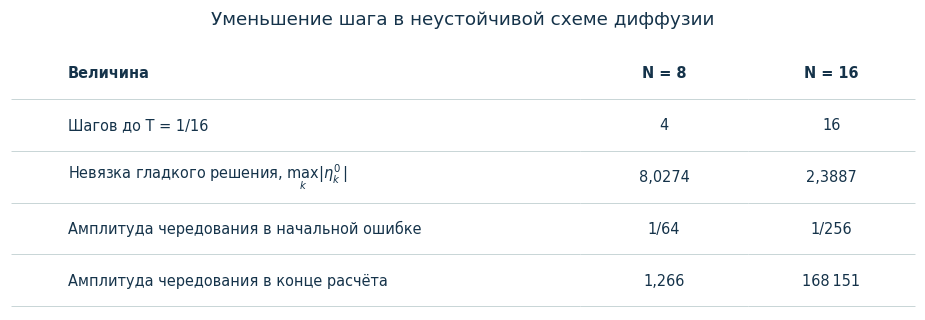

In [2]:
def grid_pair_choices(values):
    return [(f"{n} и {2*n}", n) for n in values]


def table_style(table):
    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#B9CACC")
        cell.set_linewidth(.5)
        cell.visible_edges = "B"
        cell.set_text_props(color=INK, ha="left" if col==0 else "center")
        if row==0:
            cell.set_text_props(weight="bold")


def unstable_values(N):
    tau = 1/N**2
    M = N**2//16
    residual = abs(np.expm1(-4*np.pi**2*tau) + 4*np.sin(np.pi/N)**2)/tau
    log_amp = M*np.log10(3.)-2*np.log10(N)
    return M, residual, log_amp


def amp_label(log_amp):
    if log_amp <= 4:
        return decimal(10**log_amp, 3)
    if log_amp < 6:
        return f"{10**log_amp:,.0f}".replace(",", "\u202f")
    exponent = int(np.floor(log_amp))
    mantissa = decimal(10**(log_amp-exponent), 3)
    return mantissa + " · " + rf"$10^{{{exponent}}}$"


def vanishing_figure(N=8):
    columns = []
    for n in (N, 2*N):
        M, residual, log_amp = unstable_values(n)
        columns.append([str(M), decimal(residual, 4), "1/"+str(n*n), amp_label(log_amp)])
    labels = ["Шагов до T = 1/16", r"Невязка гладкого решения, $\max_k|\eta_k^0|$",
              "Амплитуда чередования в начальной ошибке", "Амплитуда чередования в конце расчёта"]
    fig, ax = plt.subplots(figsize=(8.3,2.8), constrained_layout=True)
    ax.axis("off")
    tab = ax.table(cellText=list(zip(labels,*columns)), colLabels=["Величина",f"N = {N}",f"N = {2*N}"],
                   colWidths=[.63,.185,.185], cellLoc="center", bbox=[0,.01,1,.94])
    table_style(tab)
    ax.set_title("Уменьшение шага в неустойчивой схеме диффузии")
    return fig

experiment(vanishing_figure, {"N": ("Число узлов",grid_pair_choices([8,16,32,64]),8)})

В точном решении чередующейся составляющей нет. Она ортогональна исходному косинусу, поэтому среднеквадратичная ошибка всего профиля как минимум равна её амплитуде. На этих сетках одновременно уменьшаются начальная ошибка и локальная невязка, а глобальная ошибка растёт.

## 5. Насколько точно оценка предсказывает ошибку?

Теперь возьмём две устойчивые схемы. Для переноса $u_t+u_x=0$ используем левую разность и $\tau=h/2$. Для диффузии $u_t=u_{xx}$ — центральную вторую разность и $\tau=h^2/4$. В обоих случаях новый слой получается усреднением соседних значений. Каждый сдвиг сохраняет среднеквадратичную норму, а такое усреднение может её только уменьшить или сохранить. Поэтому $K_T=1$.

Начальный профиль $\cos(2\pi x)$ на этот раз зададим точно. Тогда оценка принимает особенно простой вид:

$$
\underbrace{\|\mathbf U^M-\mathbf u^M\|_h}_{\text{фактическая ошибка }E}
\;\le\;
\underbrace{\sum_{s=0}^{M-1}\|\mathbf d^s\|_h}_{\text{верхняя граница }Q}.
$$

Обе стороны можно вычислить независимо. Для левой схема проходит все шаги от начального слоя до $T=1/16$. Для правой каждый отдельный шаг начинается с точного решения на соответствующем временном слое.

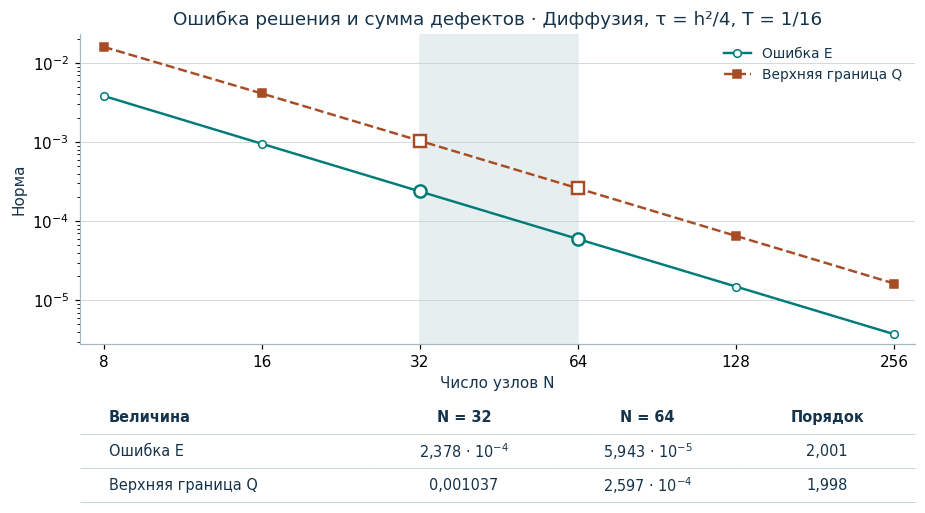

In [3]:
from functools import lru_cache


@lru_cache(maxsize=None)
def error_and_bound(N, model):
    heat = model=="heat"
    T = 1/16
    tau = 1/(4*N*N) if heat else 1/(2*N)
    M = round(T/tau)
    x = np.arange(N) / N
    initial = np.cos(2*np.pi*x)
    def exact(t):
        return np.exp(-4*np.pi**2*t)*initial if heat else np.cos(2*np.pi*(x-t))
    def step(u):
        if heat:
            return .5*u + .25*(np.roll(u,1)+np.roll(u,-1))
        return .5*(u+np.roll(u,1))
    def norm(u):
        return np.sqrt(np.mean(u*u))
    u = step(initial)
    first_defect = norm(exact(tau)-u)
    for _ in range(1,M):
        u = step(u)
    # Для косинуса при переносе нормы всех дефектов равны; при диффузии
    # их отношение равно точному множителю затухания за шаг.
    weights = np.expm1(-4*np.pi**2*T)/np.expm1(-4*np.pi**2*tau) if heat else M
    return norm(u-exact(T)), weights*first_defect


def short_value(v):
    if v >= .001:
        return f"{v:.4g}".replace(".",",")
    exponent = int(np.floor(np.log10(v)))
    return decimal(v / 10.**exponent,3) + " · " + rf"$10^{{{exponent}}}$"


def convergence_figure(model="heat", N=32, visible=(True,True)):
    grids = np.array([8,16,32,64,128,256])
    results = np.array([error_and_bound(int(n),model) for n in grids])
    fig, (ax, numbers) = plt.subplots(2,1, figsize=(8.3,4.55),
                    gridspec_kw={"height_ratios":[3.5,1.15]}, constrained_layout=True)
    ax.set_xscale("log",base=2)
    ax.set_yscale("log")
    ax.set_xlim(7.2,280)
    ax.set_ylim(.75*results.min(),1.45*results.max())
    ax.set_xticks(grids, labels=list(map(str,grids)))
    ax.axvspan(N,2*N,color="#E7EEF0")
    ax.grid(axis="y",lw=.45,color="#BECDD0")
    j = list(grids).index(N)
    entries = []
    for i,(name,color,fmt) in enumerate([("Ошибка E",TEAL,"o-"), ("Верхняя граница Q",RUST,"s--")]):
        if visible[i]:
            vals = results[:,i]
            ax.plot(grids, vals, fmt, color=color, mfc="white" if i==0 else color, ms=5, lw=1.6, label=name)
            ax.plot(grids[j:j+2], vals[j:j+2], "os"[i], mfc="white", mec=color, ms=8, mew=1.6)
            p = np.log2(vals[j]/vals[j+1])
            entries.append([name,short_value(vals[j]),short_value(vals[j+1]),decimal(p,3)])
    if any(visible):
        ax.legend(frameon=False,fontsize=9)
    tag = "Диффузия, τ = h²/4" if model=="heat" else "Перенос, τ = h/2"
    ax.set(xlabel="Число узлов N", ylabel="Норма", title=f"Ошибка решения и сумма дефектов · {tag}, T = 1/16")
    numbers.axis("off")
    if entries:
        tab = numbers.table(cellText=entries,colLabels=["Величина",f"N = {N}",f"N = {2*N}","Порядок"],
                            colWidths=[.35,.22,.22,.21],cellLoc="center",bbox=[0,0,1,1])
        table_style(tab)
    return fig

experiment(convergence_figure, {
    "model": ("Уравнение",[("Диффузия","heat"),("Перенос","transport")],"heat"),
    "N": ("Сравниваемые сетки",grid_pair_choices([8,16,32,64,128]),32),
}, ("Ошибка E","Верхняя граница Q"))

При переносе на 32 узлах фактическая ошибка равна $0{,}01352$, а верхняя граница — $0{,}01362$. Здесь сумма дефектов почти точно предсказывает результат. При диффузии на той же сетке ошибка равна $0{,}000238$, а граница — $0{,}00104$. Ранние дефекты успели затухнуть, тогда как в верхнюю оценку каждый вошёл с полной величиной.

При удвоении числа узлов ошибка переноса уменьшается примерно вдвое, ошибка диффузии — примерно вчетверо. Именно такой порядок давала **нормированная невязка** на выбранных семействах сеток. Устойчивость позволила сохранить его до конца расчёта.